In [1]:
# !uv pip install --system scikit-learn==1.5.2

try:
    from autogluon.tabular import TabularPredictor
except:
    !uv pip install -q autogluon
    from autogluon.tabular import TabularPredictor

# ## -- To use Foundation models: data ~100k rows --
# !uv pip install autogluon.tabular[tabarena]

In [2]:
# %%capture saved_prints
!uv pip install ipywidgets
!apt-get install -qq -y graphviz graphviz-dev && pip install -q pydot
!pip install -qq pygraphviz

Using Python 3.12.13 environment at: /usr
Checked 1 package in 190ms
Selecting previously unselected package libatk1.0-data.
(Reading database ... 120968 files and directories currently installed.)
Preparing to unpack .../00-libatk1.0-data_2.36.0-3build1_all.deb ...
Unpacking libatk1.0-data (2.36.0-3build1) ...
Selecting previously unselected package libatk1.0-0:amd64.
Preparing to unpack .../01-libatk1.0-0_2.36.0-3build1_amd64.deb ...
Unpacking libatk1.0-0:amd64 (2.36.0-3build1) ...
Selecting previously unselected package libgtk2.0-common.
Preparing to unpack .../02-libgtk2.0-common_2.24.33-2ubuntu2.1_all.deb ...
Unpacking libgtk2.0-common (2.24.33-2ubuntu2.1) ...
Selecting previously unselected package libxcomposite1:amd64.
Preparing to unpack .../03-libxcomposite1_1%3a0.4.5-1build2_amd64.deb ...
Unpacking libxcomposite1:amd64 (1:0.4.5-1build2) ...
Selecting previously unselected package libgtk2.0-0:amd64.
Preparing to unpack .../04-libgtk2.0-0_2.24.33-2ubuntu2.1_amd64.deb ...
Unpack

In [3]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [4]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

In [5]:
import random
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Image

import itertools
from tqdm.auto import tqdm
from time import time, sleep

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output="pandas")

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# plt.style.use("ggplot")

In [6]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 10,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [7]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

## =================================================================================

TARGET, ID = 'is_fraud', 'id'

# train[TARGET] = train[TARGET].map({True: 1, False: 0})
# orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()
bol = train.select_dtypes(include=[bool]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
bool_cols = [c for c in bol if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+bool_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total Boolean: {len(bool_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699960, 25)
Test shape: (299984, 24)
Orig shape: (20000, 25)

Frame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 13
Total Categorical: 5
Total Boolean: 6
Total base features: 24


In [8]:
train.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [9]:
# !rm -r /kaggle/working

In [10]:
MODELS_PATH = "/kaggle/working/ag_Fraud/"
# !rm -r {MODELS_PATH}

In [11]:
## -- RUN 1: Use train data -- 

predictor = TabularPredictor(
            label = TARGET,
     # problem_type = "regression",
      eval_metric = 'roc_auc',
             path = MODELS_PATH,
).fit(
           train_data = train,
              presets = 'best_quality', # 'v1_best_quality_v150', v1_original_best_quality_v150'
        num_bag_folds = 5,
     dynamic_stacking = False, # d=True
     num_stack_levels = 1, # 0 if False
           time_limit = 3600*11,
           # auto_stack = False,
         # num_bag_sets = 2,
          # ag_args_fit = {'num_cpus': os.cpu_count()},
)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.12.13
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Oct 22 16:37:21 UTC 2026
CPU Count:          4
Pytorch Version:    2.10.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       29.76 GB / 31.35 GB (94.9%)
Disk Space Avail:   19.50 GB / 19.52 GB (99.9%)
Presets specified: ['best_quality']
Using hyperparameters preset: hyperparameters='zeroshot'
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=5, num_bag_sets=1
Beginning AutoGluon training ... Time limit = 39600s
AutoGluon will save models to "/kaggle/working/ag_Fraud"
Train Data Rows:    699960
Train Data Columns: 24
Label Column:       is_fraud
AutoGluon infers your prediction problem is: 'binary' (because only two unique label-values observed).
	2 unique label values:  [np.float64(0.0), np.float64(1.0)]
	If 'binary' is not the co

(raylet) Task _ray_fit failed due to oom. There are infinite oom retries remaining, so the task will be retried. Error: 1 worker(s) were killed due to the node running low on memory. Memory on the node (IP: 172.19.2.2, ID: 3971f9ac316da3d17cd8ca7b1cb7a2c9c5f4b1cd727de7bc8baec554) was 28.50GB / 30.00GB (0.950012), which exceeds the memory usage threshold of 0.950000; Object store memory usage: [- objects spillable: 1; - bytes spillable: 5600084; - objects unsealed: 0; - bytes unsealed: 0; - objects in use: 8; - bytes in use: 109200549; - objects evictable: 0; - bytes evictable: 0; ; - objects created by worker: 8; - bytes created by worker: 109200549; - objects restored: 0; - bytes restored: 0; - objects received: 0; - bytes received: 0; - objects errored: 0; - bytes errored: 0; ; Eviction Stats:; (global lru) capacity: 9391382937; (global lru) used: 0%; (global lru) num objects: 0; (global lru) num evictions: 0; (global lru) bytes evicted: 0]; Ray killed 1 worker(s) based on the killin

	0.9417	 = Validation score   (roc_auc)
	7880.2s	 = Training   runtime
	32.22s	 = Validation runtime
Fitting model: CatBoost_r9_BAG_L1 ... Training model for up to 4900.62s of the 18105.85s of remaining time.
	Fitting 5 child models (S1F1 - S1F5) | Fitting with ParallelLocalFoldFittingStrategy (4 workers, per: cpus=1, gpus=0, memory=4.61%)
	0.945	 = Validation score   (roc_auc)
	1941.12s	 = Training   runtime
	9.43s	 = Validation runtime
Fitting model: LightGBM_r96_BAG_L1 ... Training model for up to 2951.15s of the 16156.38s of remaining time.
	Fitting 5 child models (S1F1 - S1F5) | Fitting with ParallelLocalFoldFittingStrategy (4 workers, per: cpus=1, gpus=0, memory=2.00%)
	0.9457	 = Validation score   (roc_auc)
	920.52s	 = Training   runtime
	380.04s	 = Validation runtime
Fitting model: NeuralNetTorch_r22_BAG_L1 ... Training model for up to 1947.51s of the 15152.74s of remaining time.
	Fitting 5 child models (S1F1 - S1F5) | Fitting with ParallelLocalFoldFittingStrategy (4 workers, p

In [12]:
## -- Get Summary --

print(f"-> Problem type: {predictor.problem_type}")
print(f"-> Total models: {len(predictor.model_names())}")
print(f"-> Best model  : {predictor.model_best}\n") 

leaderboard = predictor.leaderboard(silent=True)
leaderboard.style.background_gradient(subset=['score_val'], cmap='Spectral')

-> Problem type: binary
-> Total models: 39
-> Best model  : WeightedEnsemble_L3



,model,score_val,eval_metric,pred_time_val,fit_time,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L3,0.946844,roc_auc,1089.094888,29006.217300,0.229239,173.668969,3,True,39
1,WeightedEnsemble_L2,0.946822,roc_auc,682.454526,9691.042399,0.172558,84.739025,2,True,21
2,CatBoost_r9_BAG_L2,0.946353,roc_auc,973.242702,26590.204115,6.245811,615.454569,2,True,37
3,CatBoost_BAG_L1,0.946113,roc_auc,2.323518,4670.259559,2.323518,4670.259559,1,True,5
4,LightGBM_r131_BAG_L2,0.946093,roc_auc,1017.064413,26250.829429,50.067522,276.079884,2,True,35
5,CatBoost_BAG_L2,0.946052,roc_auc,968.085131,26656.014547,1.088240,681.265002,2,True,26
6,LightGBM_r131_BAG_L1,0.946008,roc_auc,259.943864,518.049986,259.943864,518.049986,1,True,14
7,CatBoost_r177_BAG_L1,0.945969,roc_auc,1.413308,1345.587156,1.413308,1345.587156,1,True,12
8,CatBoost_r177_BAG_L2,0.945965,roc_auc,968.180434,26316.421362,1.183543,341.671816,2,True,33
9,LightGBM_BAG_L2,0.945725,roc_auc,970.633744,26042.006260,3.636853,67.256714,2,True,23


In [13]:
# ## -- RUN 2: Use original data as extra learning input --
# predictor.fit_pseudolabel(
#                 orig,
#                 use_ensemble = True,
#                 fit_ensemble = True, 
#                 time_limit   = 3600*2,
# )

In [14]:
# ## -- Get Summary -- 
# print(f"-> Total models : {len(predictor.model_names())}")
# print(f"-> Best model   : {predictor.model_best}\n") 

# ## -- RUN 2 RESULTS -- 
# leaderboard = predictor.leaderboard(silent=True)
# leaderboard.style.background_gradient(subset=["score_val"], cmap="Spectral")

In [15]:
## -- Create folder directory to save predictions --
SAVE_PATH = "/kaggle/working/AG_preds/"
# FILE_NAME = f"ag_{TARGET}_orig.parquet"

!mkdir {SAVE_PATH}

print(f"File path created: {SAVE_PATH}")

File path created: /kaggle/working/AG_preds/


In [16]:
def make_best_predictions(predictor, df=None, save_path=SAVE_PATH, data_type=None, use_distill=False):
    df_1 = df.copy()

    if TARGET in df_1.columns: df_1 = df_1.drop(columns=[TARGET])

    if use_distill:
        print("⧗ Exporting distilled model predictions... ", end="")
        distilled_model_names = predictor.distill()
        # ldr = predictor.leaderboard()
        model_to_deploy = distilled_model_names[0]
        if predictor.problem_type == 'regression':
            preds = predictor.predict(df_1, model=model_to_deploy)
        elif predictor.problem_type == 'binary':
            preds = predictor.predict_proba(df_1, model=model_to_deploy, as_pandas=False, as_multiclass=False)
        else:
            preds = predictor.predict(df_1, model=model_to_deploy, as_pandas=False)
        fila_name = f"{save_path}agDist_{TARGET.replace(" ", "")}_{data_type}.npy"
        np.save(fila_name, preds)
    else:
        print("⧗ Exporting best model predictions... ", end="")
        if predictor.problem_type == 'regression':
            preds = predictor.predict(df_1)
        elif predictor.problem_type == 'binary':
            preds = predictor.predict_proba(df_1, as_pandas=False, as_multiclass=False)
        else:
            preds = predictor.predict(df_1, as_pandas=False)
        fila_name = f"{save_path}agBest_{TARGET.replace(" ", "")}_{data_type}.npy"
        np.save(fila_name, preds)

    print(f"✓ Finished ({len(preds)}) samples")
    print(fila_name)

    return preds

print('Prediction function ready!')

Prediction function ready!


In [17]:
# %%time

# final_oof = make_best_predictions(
#     predictor,
#     df=orig,
#     save_path=SAVE_PATH,
#     data_type="orig",
#     # use_distill=True,
# )

# print()
# final_oof

In [18]:
# %%time

# final_train = make_best_predictions(
#     predictor,
#     df=train,
#     save_path=SAVE_PATH,
#     data_type="trn", 
#     # use_distill=True,
# )

# print()
# final_train

In [19]:
# %%time

# final_test = make_best_predictions(
#     predictor,
#     df=test,
#     save_path=SAVE_PATH,
#     data_type="tst",
#     # use_distill=True, 
# )

# print()
# final_test

In [20]:
## -- Make submission --
final_preds = predictor.predict_proba(test, as_pandas=False, as_multiclass=False)
final_score = np.round(leaderboard.score_val.max(), 5)

n = f"submit_AUTOGLUON_{str(final_score).split('.')[1]}.csv"
submit[TARGET] = final_preds
submit.to_csv(n, index=False)

print('Submission file exported as ->', n)
submit.head()

Submission file exported as -> submit_AUTOGLUON_94684.csv


,id,is_fraud
0,699960,0.000222
1,699961,0.000102
2,699962,0.085258
3,699963,0.001153
4,699964,0.001362


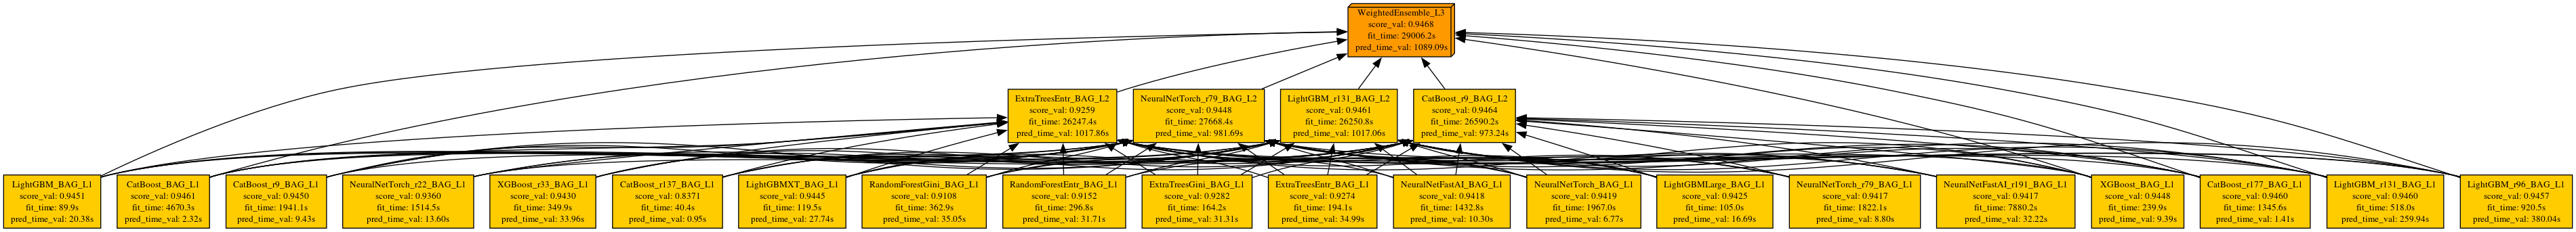

In [21]:
predictor.plot_ensemble_model(filename='ensemble_model.png')
display(Image(f'{MODELS_PATH}ensemble_model.png'))

In [22]:
## -- Extract model scores --
result_df = leaderboard[['model', 'score_val']]

max_score = result_df['score_val'].max()
min_score = result_df['score_val'].min()

result_df

,model,score_val
0,WeightedEnsemble_L3,0.946844
1,WeightedEnsemble_L2,0.946822
2,CatBoost_r9_BAG_L2,0.946353
3,CatBoost_BAG_L1,0.946113
4,LightGBM_r131_BAG_L2,0.946093
5,CatBoost_BAG_L2,0.946052
6,LightGBM_r131_BAG_L1,0.946008
7,CatBoost_r177_BAG_L1,0.945969
8,CatBoost_r177_BAG_L2,0.945965
9,LightGBM_BAG_L2,0.945725


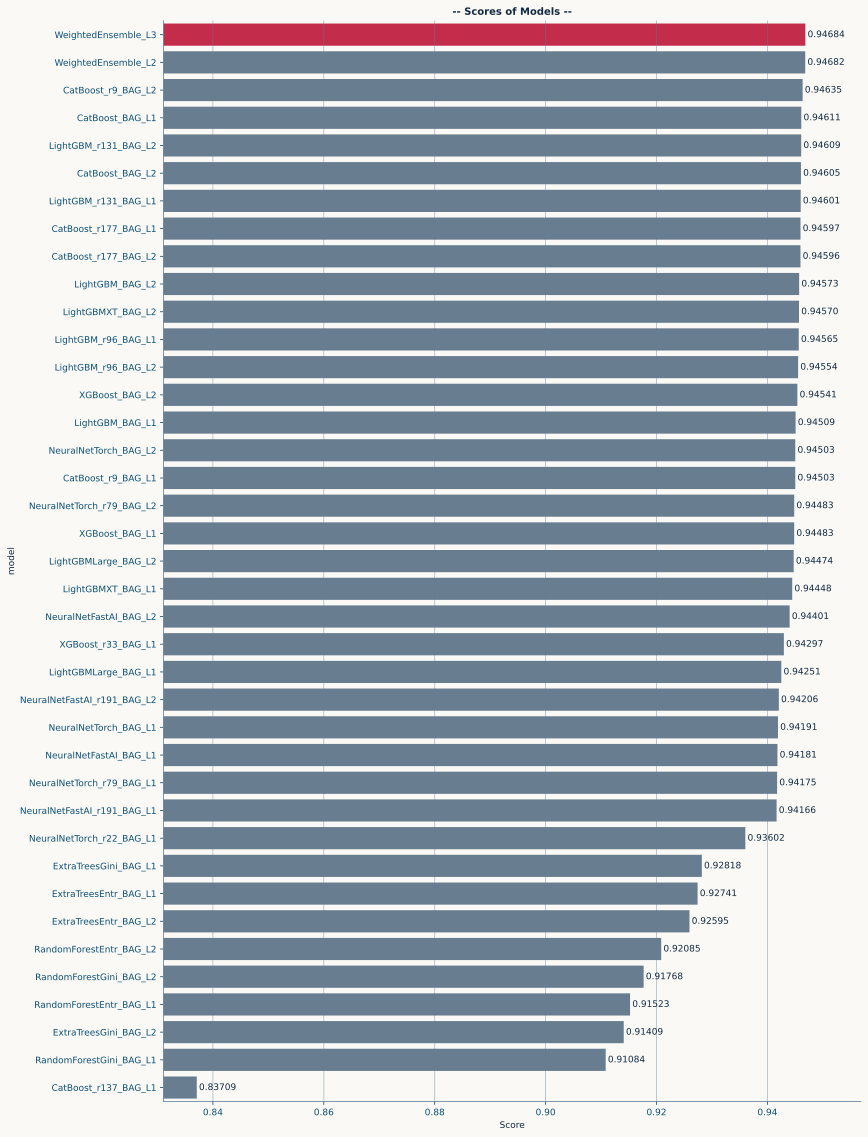

In [23]:
## -- Plot model scores --
plt.figure(figsize=(12.5, len(result_df)*0.5))
# plt.stem(
#     result_df.index,
#     result_df[0],
#     orientation = 'horizontal',
#     bottom = min_score - 0.0055,
#     markerfmt = 'C3o'
# )

sns.barplot(
    result_df, x=result_df['score_val'], y=result_df['model'], #width=0.5,
    palette=[MUTED if c < max_score else CRIM for c in result_df['score_val']]
)
plt.xlim(min_score - 0.006, max_score + 0.01)
plt.xlabel('Score')
plt.title('-- Scores of Models --')

for i, value in enumerate(result_df['score_val']):
    plt.text(value+4e-4, i, f'{abs(value):.5f}', ha='left', va='center')

plt.grid(True, axis='x')
# plt.tight_layout()
plt.show()

In [24]:
# predictor.model_names()

In [25]:
# ## -- Permutation Feature Importances --
# feat_imp = predictor.feature_importance(
#                         data = X_test,
#                         # time_limit = 3600,
#                         # model = 'LightGBM_BAG_L1',
#                         # features = None,
#                         # feature_stage = 'transformed',
#                         # subsample_size = 5000,
#                         # num_shuffle_sets = 10,
#                         # include_confidence_band = True,
#                         confidence_level = 0.95,
#                         # silent = False
# ) 

# feat_imp.style.background_gradient(subset=["importance"], cmap="Spectral")

# plt.figure(figsize=(18, 35))
# sns.barplot(data=feat_imp, y=feat_imp.index, x=feat_imp.importance)
# plt.tick_params(axis='y', which='major', labelcolor='r')
# plt.title("Top Features by Permutation")
# plt.tight_layout()
# plt.show()

In [26]:
print(f"""
{'-'*48}
{'█'*5} | - AUTOGLUON NOTEBOOK COMPLETE! - | {'█'*5}
{'-'*48}
""")


------------------------------------------------
█████ | - AUTOGLUON NOTEBOOK COMPLETE! - | █████
------------------------------------------------



In [27]:
## -- OPTIONAL: Clear stored files in memory --
!rm -r {MODELS_PATH}
print("⚙️ All models deleted!")

⚙️ All models deleted!


In [28]:
# !rm -r /kaggle/working